# Unified models

One setup on every track, so the inputs are the only difference between them. Decisions use walk-forward first, with the 80/10/10 split as a second view. The test split stays locked.

| Input set | Inputs per day |
| --- | --- |
| No news, no features | Log return, 6 date features: 7 |
| No news, with indicators | Those, plus 2 technical indicators: 9 |
| News | Log return, 6 date features, 7 news features: 14 |
| News and indicators | All of the above: 16 |

**Models:** RNN and LSTM (up to 200 epochs, patience 10, best weights restored) and XGBoost (up to 500 trees, patience 30, depth 4, learning rate 0.05, full 30-day windows).

**Early stopping** uses the last 10% of known days, never days being scored. Scaling is fit on the rows before that slice.

All runs use common dates, standardization and the 1-day horizon.

In [1]:
from pathlib import Path
import sys

import pandas as pd

# notebook is in training/benchmarking/notebooks, parents[1] points to training/
sys.path.insert(0, str(Path.cwd().parents[1]))

from benchmarking.data import (
    NEWS_WITH_FEATURES,
    NEWS_WITH_FEATURES_AND_TECH,
    NO_NEWS_NO_FEATURES,
    NO_NEWS_WITH_FEATURES,
    UNIFIED_TRACKS,
)
from benchmarking.experiment import ExperimentConfig, run_experiment
from benchmarking.fit_check import plot_saved_training_fit, plot_validation_fit
from benchmarking.metrics import summarize_seeds
from benchmarking.models import UNIFIED_MODELS
from benchmarking.result_plots import (
    plot_split_results,
    plot_track_comparisons,
    plot_walk_forward_intervals,
    plot_walk_forward_rounds,
)
from benchmarking.walk_forward import (
    WalkForwardConfig,
    compare_tracks,
    run_walk_forward,
    score_walk_forward,
    walk_forward_intervals,
)

RESULTS_DIR = Path.cwd().parent / "results"
RESULTS_DIR.mkdir(exist_ok=True)
SEEDS = (42, 43, 44, 45, 46)

pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:.4f}".format)

## Training

Both cells skip work that's already saved. Delete the `unified_*` files in `results/` to retrain after changing any settings.

In [2]:
# 80/10/10 split: 60 fits
if not (RESULTS_DIR / "unified_split_seed_metrics.csv").exists():
    runs = [
        run_experiment(
            ExperimentConfig(
                track=track,
                models=UNIFIED_MODELS,
                horizons=(1,),
                seeds=SEEDS,
                common_dates=True,
                standardize=True,
                early_stopping_fraction=0.1,
            )
        )
        for track in UNIFIED_TRACKS
    ]
    metrics = pd.concat([run["metrics"] for run in runs], ignore_index=True)
    pd.concat([run["predictions"] for run in runs], ignore_index=True).to_csv(
        RESULTS_DIR / "unified_split_predictions.csv", index=False
    )
    summarize_seeds(metrics).to_csv(RESULTS_DIR / "unified_split_seed_summary.csv", index=False)
    metrics.to_csv(RESULTS_DIR / "unified_split_seed_metrics.csv", index=False)

In [3]:
# Walk-forward: 480 fits, and continues where it stopped if interrupted
for track in UNIFIED_TRACKS:
    run_walk_forward(
        WalkForwardConfig(track=track, models=UNIFIED_MODELS, seeds=SEEDS),
        RESULTS_DIR / "unified_walk_forward_predictions.csv",
    )

## Load saved results

Run this and the setup cell to use any cell below without retraining.

In [4]:
walk_forward = pd.read_csv(RESULTS_DIR / "unified_walk_forward_predictions.csv")
split_predictions = pd.read_csv(RESULTS_DIR / "unified_split_predictions.csv")
split_metrics = pd.read_csv(RESULTS_DIR / "unified_split_seed_metrics.csv")
split_validation = split_predictions[split_predictions["split"] == "validation"]


def scale_mse(table, columns):
    """Show tiny MSE values multiplied by 10,000."""
    return table.assign(**{column: table[column] * 1e4 for column in columns})

## Walk-forward

### Walk-forward: results with confidence intervals

781 scored days. `oos_r2` is R² against the train-mean baseline. An interval that includes 0 can't be told apart from the baseline. MSE values are shown multiplied by 10,000.

In [5]:
intervals = walk_forward_intervals(walk_forward)
intervals.to_csv(RESULTS_DIR / "unified_walk_forward_intervals.csv", index=False)
scale_mse(intervals, ["mse", "baseline_mse"]).drop(columns="horizon")

,track,model,days,mse,baseline_mse,oos_r2,oos_r2_lower,oos_r2_upper,directional_accuracy,always_up_accuracy,direction_edge,direction_edge_lower,direction_edge_upper
0,no_news_no_feature_engineering,RNN,781,12.1328,11.5200,-0.0532,-0.0876,-0.0255,0.5173,0.5493,-3.2010,-6.7868,0.4609
1,no_news_no_feature_engineering,LSTM,781,11.7814,11.5200,-0.0227,-0.0430,-0.0056,0.5027,0.5493,-4.6607,-8.4251,-1.3310
2,no_news_no_feature_engineering,XGBoost,781,11.8736,11.5200,-0.0307,-0.0517,-0.0123,0.5206,0.5493,-2.8681,-5.5570,-0.4091
3,no_news_with_feature_engineering,RNN,781,12.1005,11.5200,-0.0504,-0.0921,-0.0164,0.5260,0.5493,-2.3303,-5.9417,0.9738
4,no_news_with_feature_engineering,LSTM,781,12.0072,11.5200,-0.0423,-0.0765,-0.0152,0.4973,0.5493,-5.1985,-8.8611,-2.1767
5,no_news_with_feature_engineering,XGBoost,781,11.8933,11.5200,-0.0324,-0.0589,-0.0100,0.5229,0.5493,-2.6376,-5.5058,-0.2305
6,news_with_feature_engineering,RNN,781,12.3274,11.5200,-0.0701,-0.1029,-0.0443,0.5111,0.5493,-3.8156,-7.0423,-0.7939
7,news_with_feature_engineering,LSTM,781,11.8562,11.5200,-0.0292,-0.0470,-0.0130,0.5150,0.5493,-3.4315,-6.7350,-0.5627
8,news_with_feature_engineering,XGBoost,781,11.7920,11.5200,-0.0236,-0.0377,-0.0115,0.5124,0.5493,-3.6876,-6.1204,-1.5365
9,news_with_feature_engineering_and_tech,RNN,781,12.4166,11.5200,-0.0778,-0.1219,-0.0425,0.5132,0.5493,-3.6108,-6.7356,-0.4097


### Walk-forward: all scored days

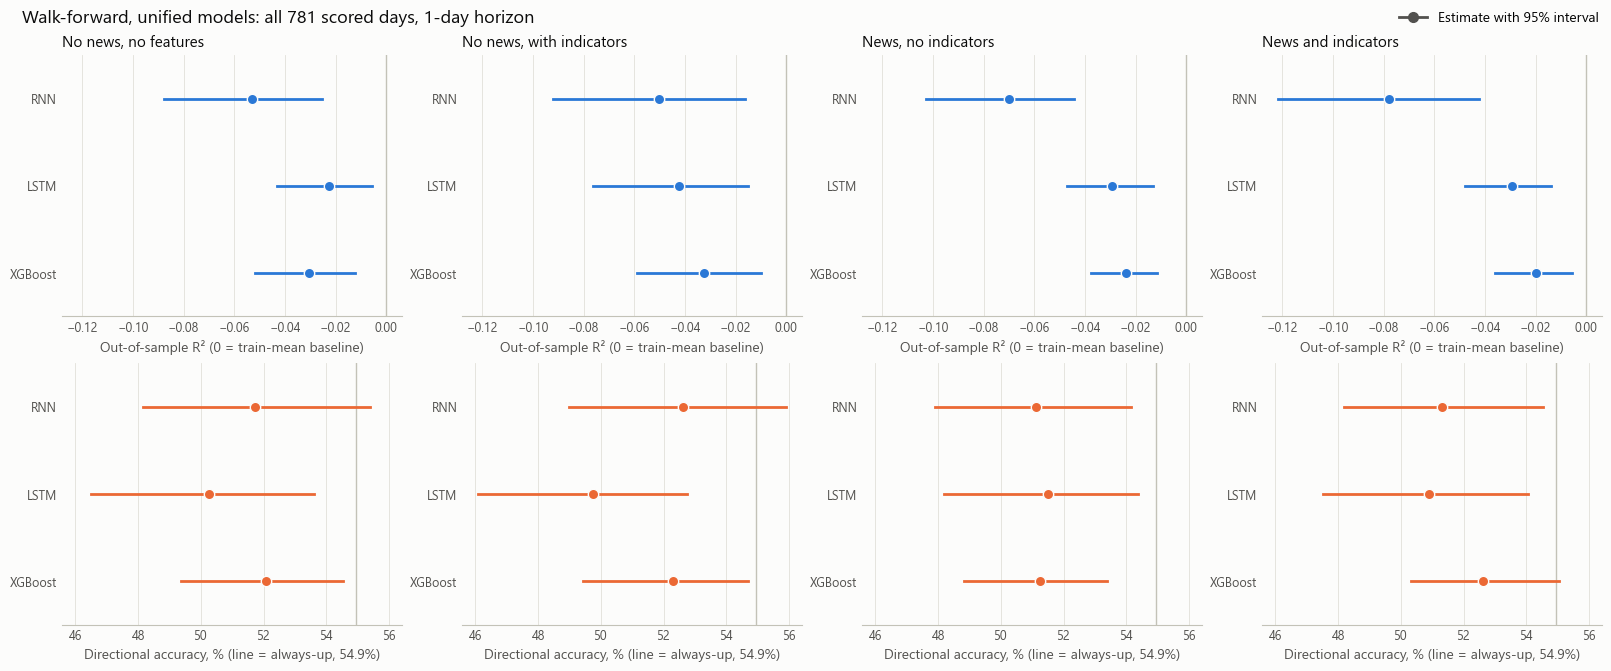

In [6]:
plot_walk_forward_intervals(intervals, title="Walk-forward, unified models: all 781 scored days, 1-day horizon")

### Walk-forward: round by round

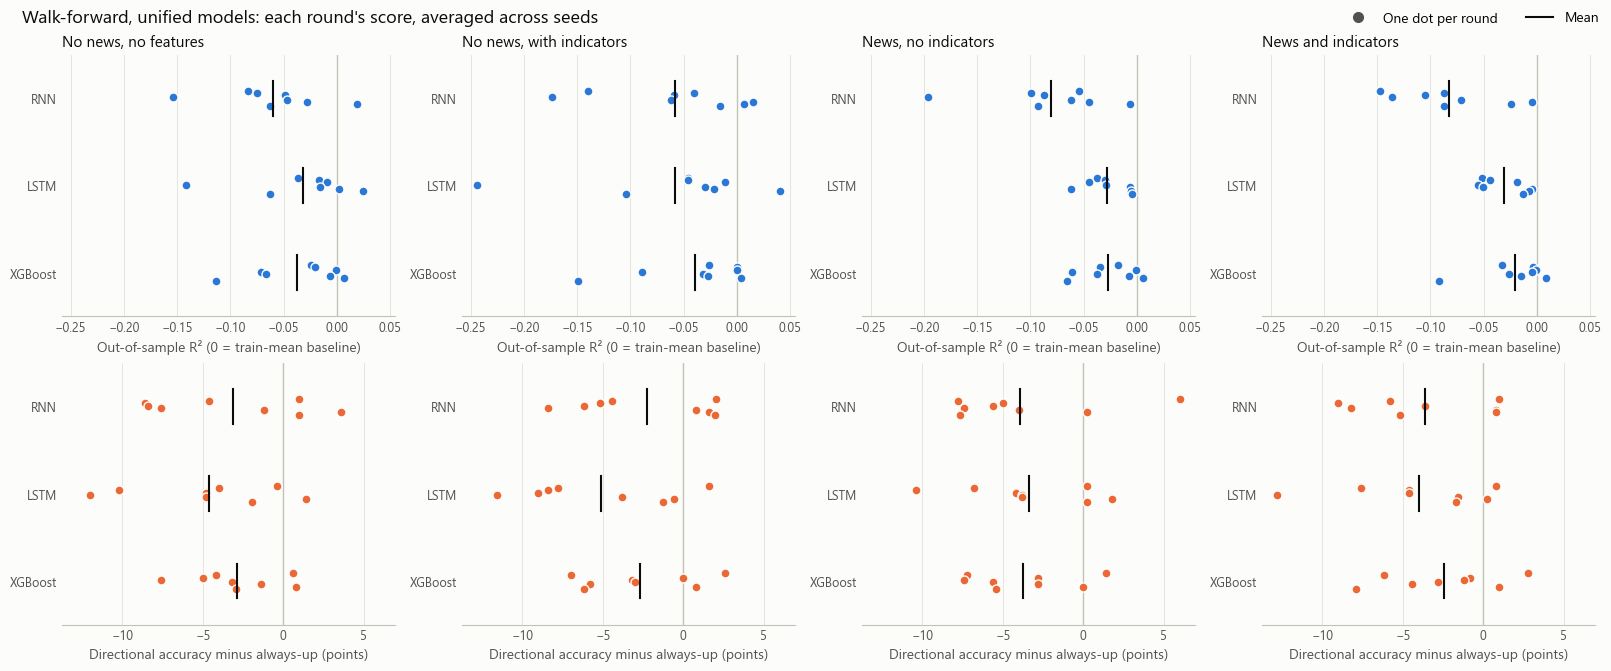

In [7]:
plot_walk_forward_rounds(
    score_walk_forward(walk_forward, by_round=True),
    title="Walk-forward, unified models: each round's score, averaged across seeds",
)

## 80/10/10 split

### 80/10/10: full training across seeds

The 123 validation days, which aren't used for early stopping.

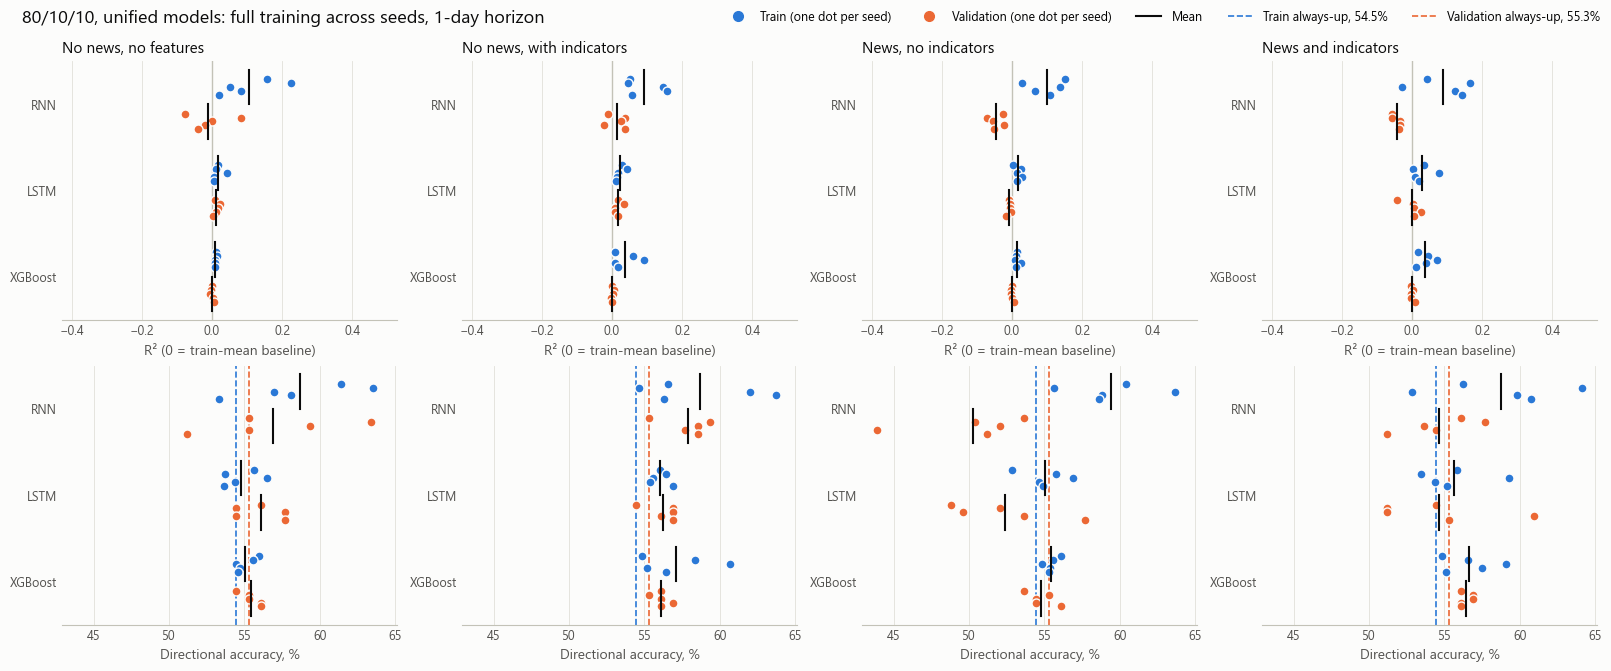

In [8]:
plot_split_results(split_metrics, title="80/10/10, unified models: full training across seeds, 1-day horizon")

### 80/10/10: summary table

In [9]:
pd.read_csv(RESULTS_DIR / "unified_split_seed_summary.csv").drop(columns=["horizon", "seeds"])

,track,model,split,r2_mean,r2_std,correlation_mean,correlation_std,spread_ratio_mean,spread_ratio_std,directional_accuracy_mean,directional_accuracy_std,always_up_accuracy,share_beating_baseline
0,no_news_no_feature_engineering,RNN,train,0.1067,0.0836,0.3225,0.1455,0.2334,0.0640,0.5868,0.0397,0.5446,1.0000
1,no_news_no_feature_engineering,RNN,validation,-0.0117,0.0588,0.0865,0.1240,0.2266,0.0665,0.5691,0.0463,0.5528,0.4000
2,no_news_no_feature_engineering,LSTM,train,0.0163,0.0152,0.1375,0.0734,0.0721,0.0201,0.5478,0.0127,0.5446,1.0000
3,no_news_no_feature_engineering,LSTM,validation,0.0112,0.0081,0.1456,0.0630,0.0675,0.0330,0.5610,0.0163,0.5528,1.0000
4,no_news_no_feature_engineering,XGBoost,train,0.0096,0.0026,0.3085,0.0503,0.0158,0.0017,0.5506,0.0067,0.5446,1.0000
5,no_news_no_feature_engineering,XGBoost,validation,-0.0013,0.0045,0.0099,0.1028,0.0204,0.0029,0.5545,0.0068,0.5528,0.4000
6,no_news_with_feature_engineering,RNN,train,0.0918,0.0555,0.3036,0.1028,0.2362,0.0406,0.5866,0.0396,0.5446,1.0000
7,no_news_with_feature_engineering,RNN,validation,0.0121,0.0283,0.1546,0.0437,0.2237,0.0347,0.5789,0.0156,0.5528,0.6000
8,no_news_with_feature_engineering,LSTM,train,0.0233,0.0127,0.1772,0.0515,0.0815,0.0205,0.5606,0.0061,0.5446,1.0000
9,no_news_with_feature_engineering,LSTM,validation,0.0160,0.0111,0.1459,0.0457,0.0894,0.0198,0.5626,0.0106,0.5528,1.0000


### 80/10/10: fit on training data, no news, no features

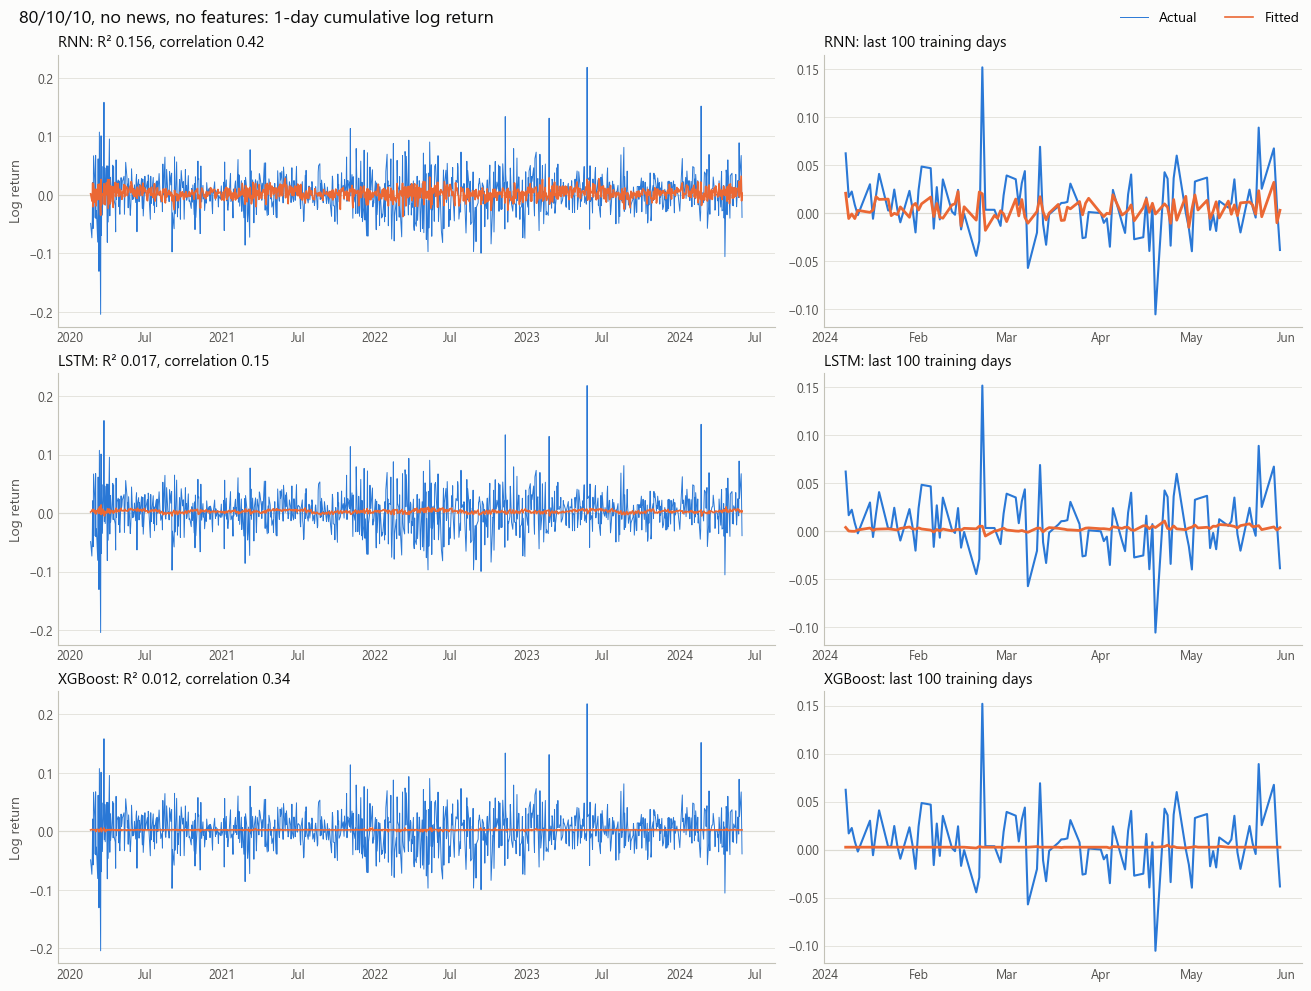

In [10]:
plot_saved_training_fit(
    split_predictions[split_predictions["track"] == NO_NEWS_NO_FEATURES],
    title="80/10/10, no news, no features",
);

### 80/10/10: fit on training data, no news, with indicators

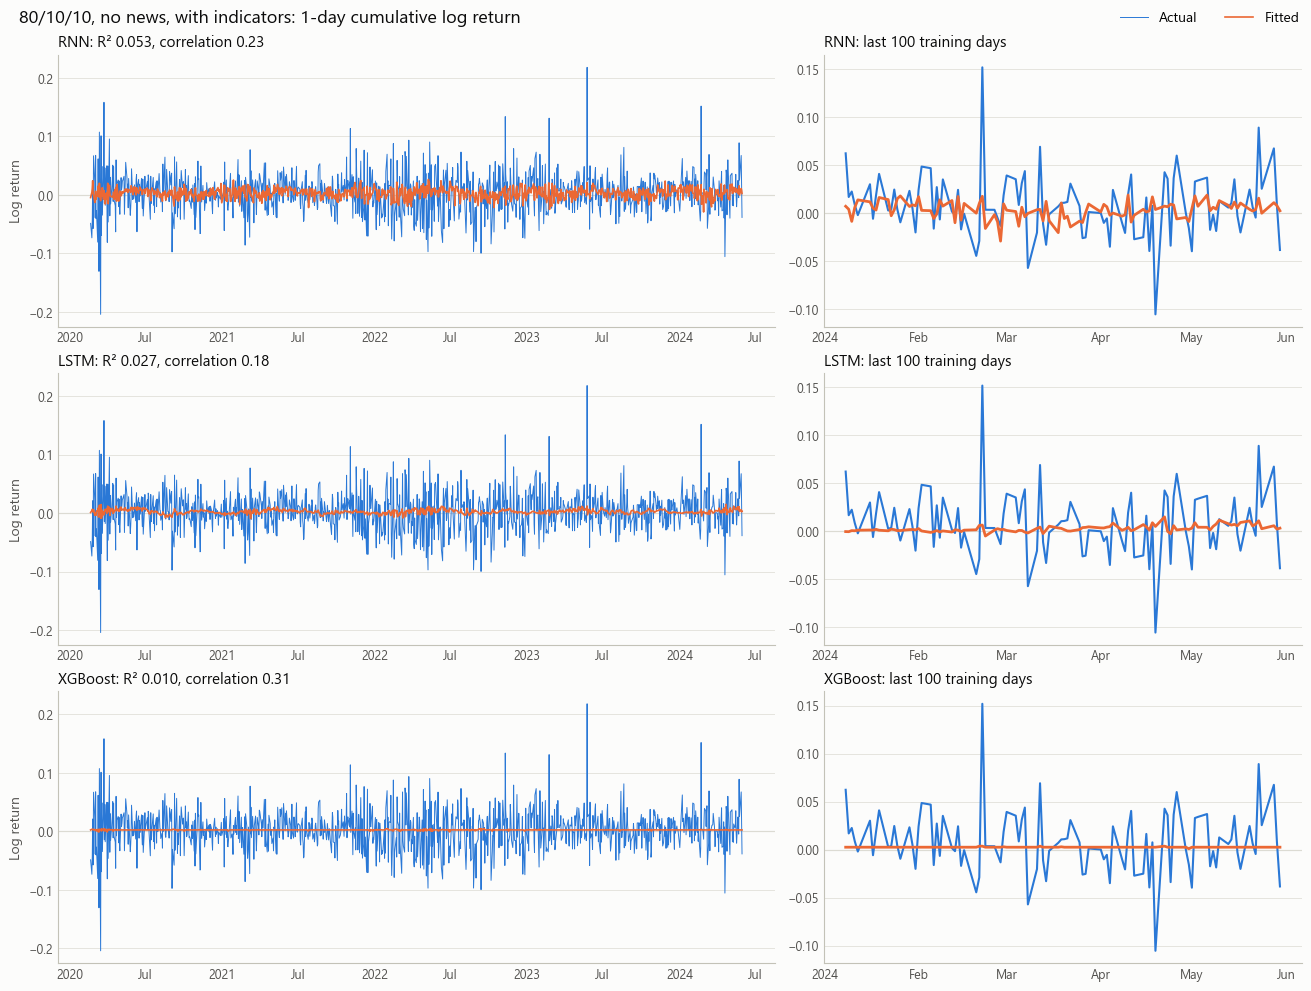

In [11]:
plot_saved_training_fit(
    split_predictions[split_predictions["track"] == NO_NEWS_WITH_FEATURES],
    title="80/10/10, no news, with indicators",
);

### 80/10/10: fit on training data, news

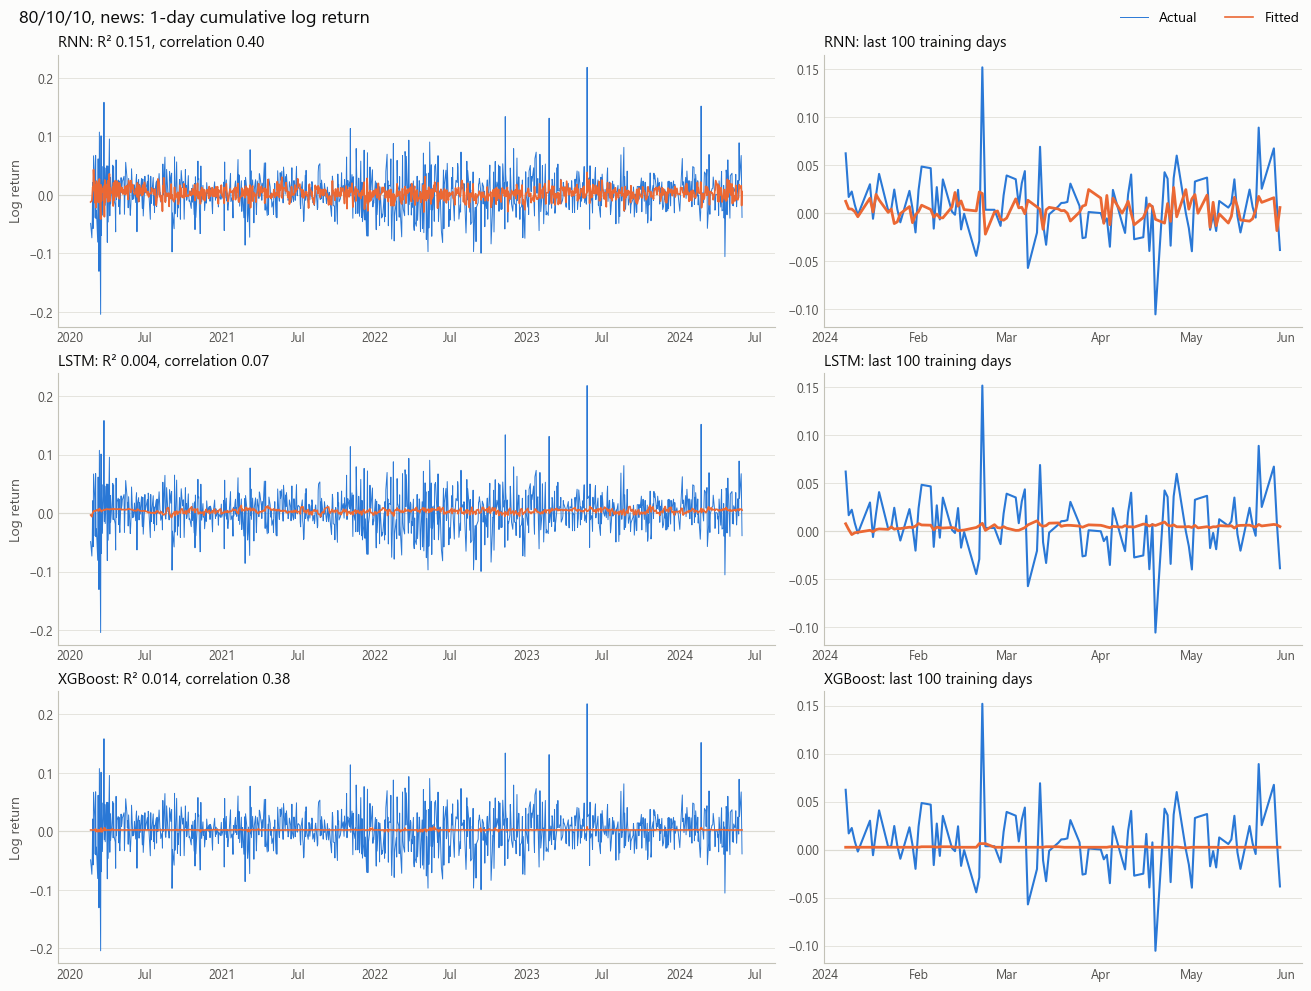

In [12]:
plot_saved_training_fit(
    split_predictions[split_predictions["track"] == NEWS_WITH_FEATURES],
    title="80/10/10, news",
);

### 80/10/10: fit on training data, news and indicators

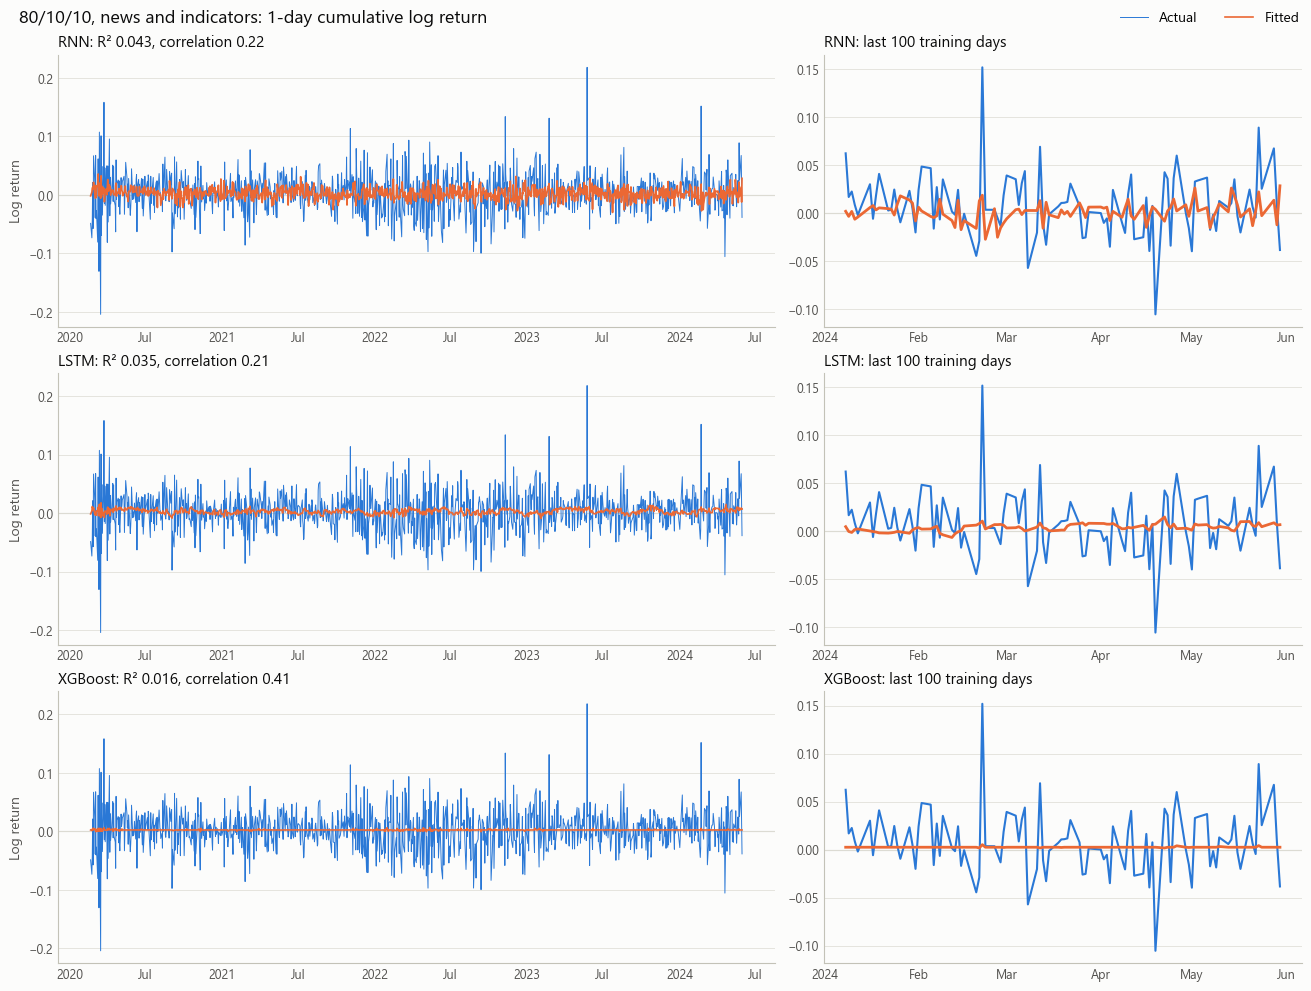

In [13]:
plot_saved_training_fit(
    split_predictions[split_predictions["track"] == NEWS_WITH_FEATURES_AND_TECH],
    title="80/10/10, news and indicators",
);

### 80/10/10: fit on validation data, no news, no features

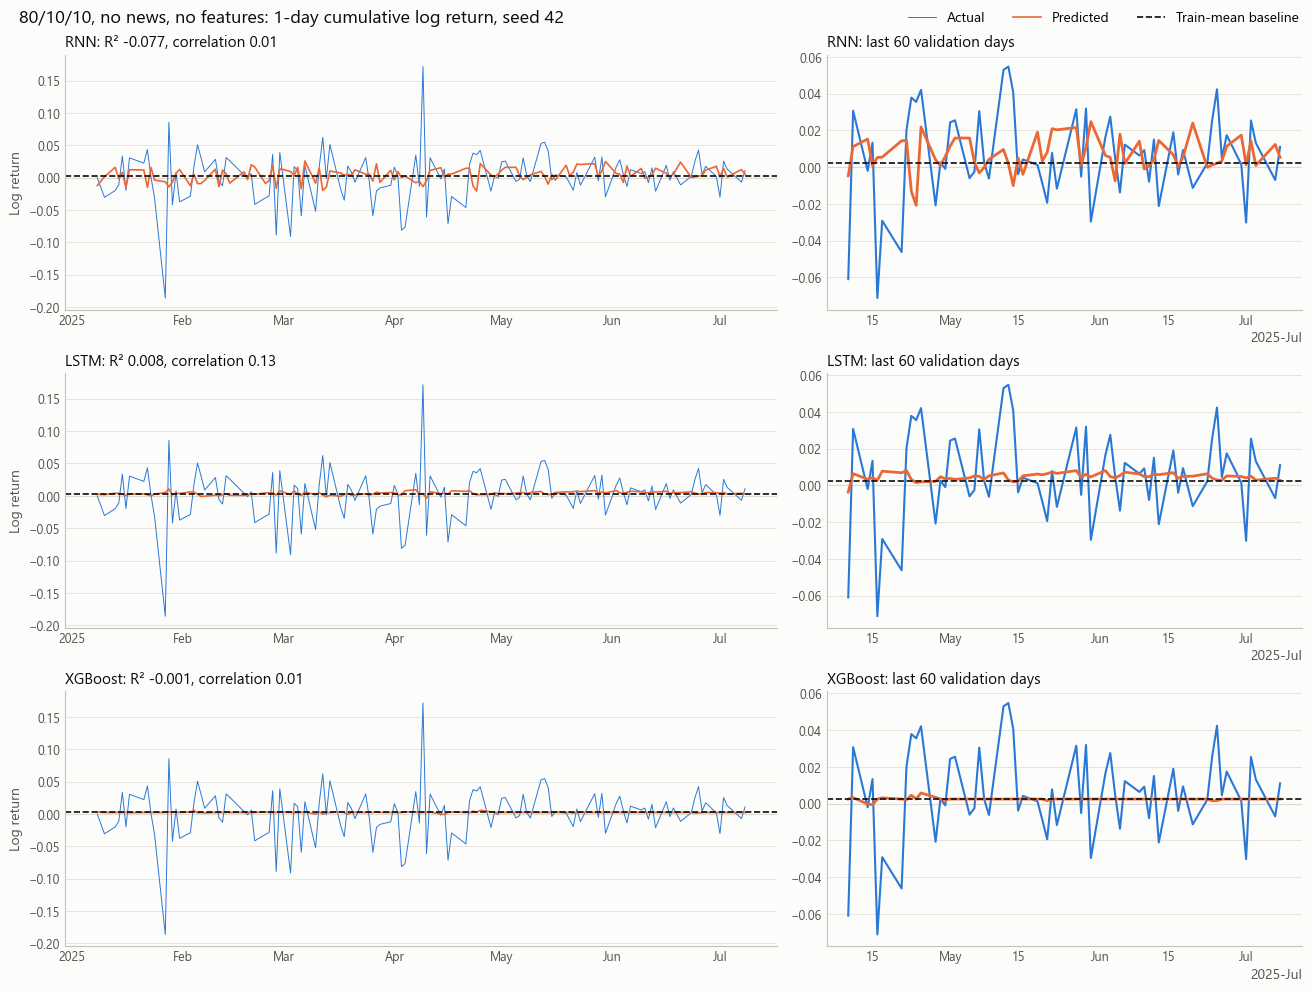

In [14]:
plot_validation_fit(
    split_predictions[split_predictions["track"] == NO_NEWS_NO_FEATURES],
    title="80/10/10, no news, no features",
);

### 80/10/10: fit on validation data, no news, with indicators

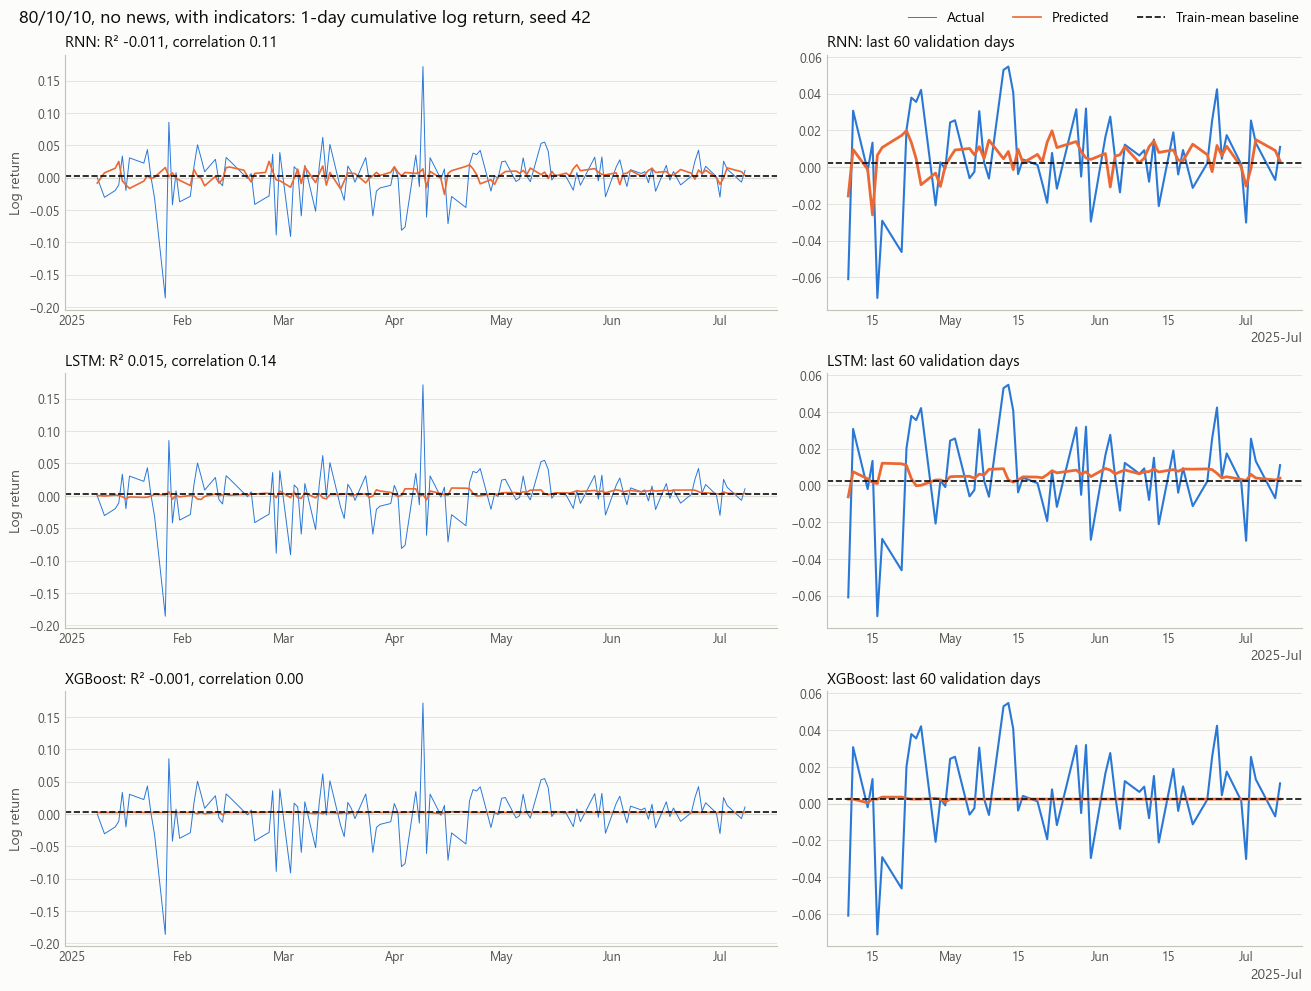

In [15]:
plot_validation_fit(
    split_predictions[split_predictions["track"] == NO_NEWS_WITH_FEATURES],
    title="80/10/10, no news, with indicators",
);

### 80/10/10: fit on validation data, news

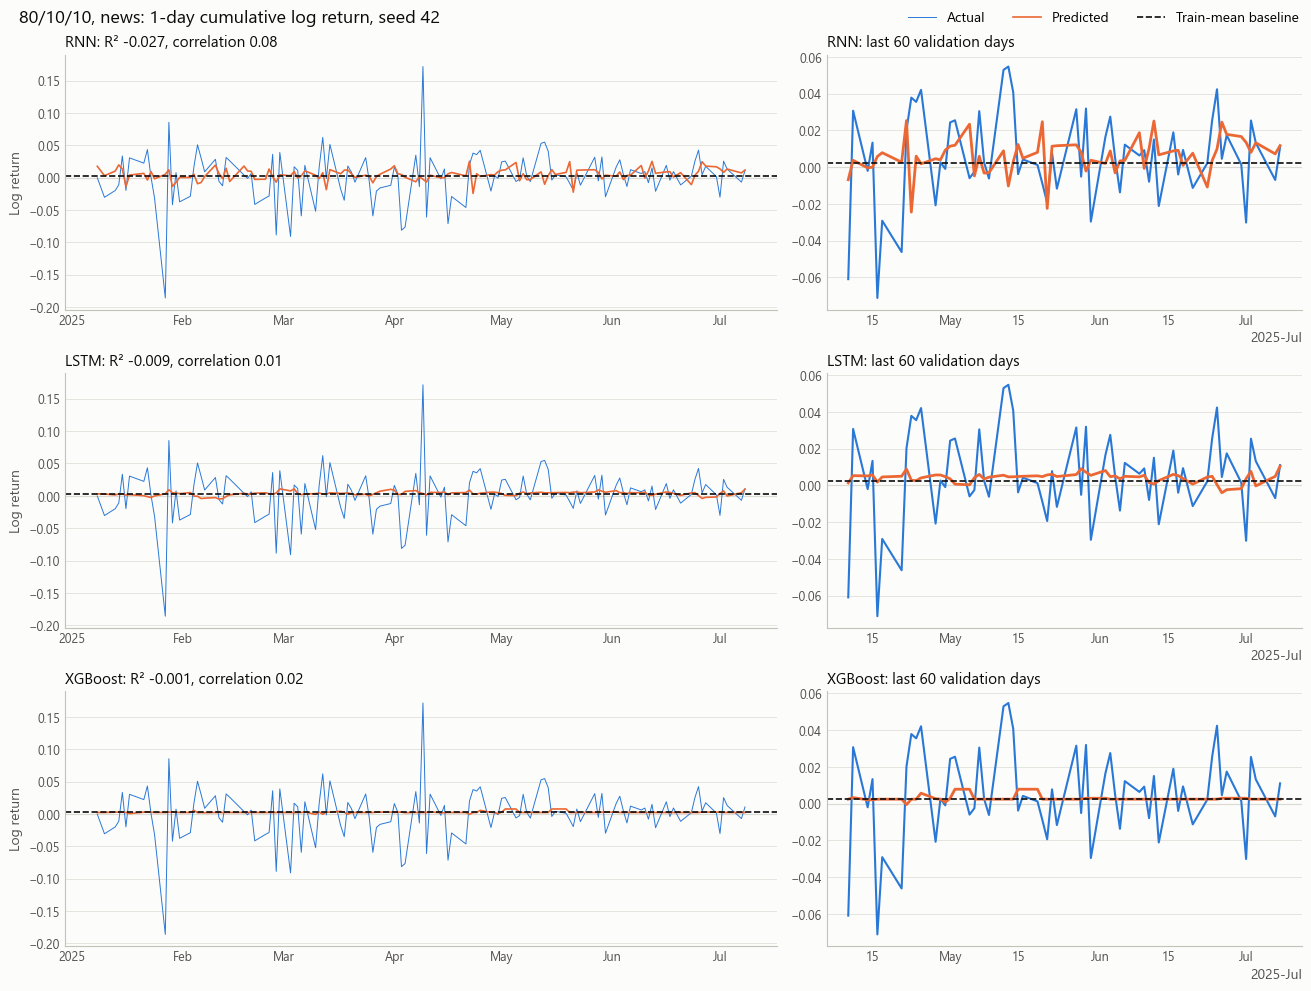

In [16]:
plot_validation_fit(
    split_predictions[split_predictions["track"] == NEWS_WITH_FEATURES],
    title="80/10/10, news",
);

### 80/10/10: fit on validation data, news and indicators

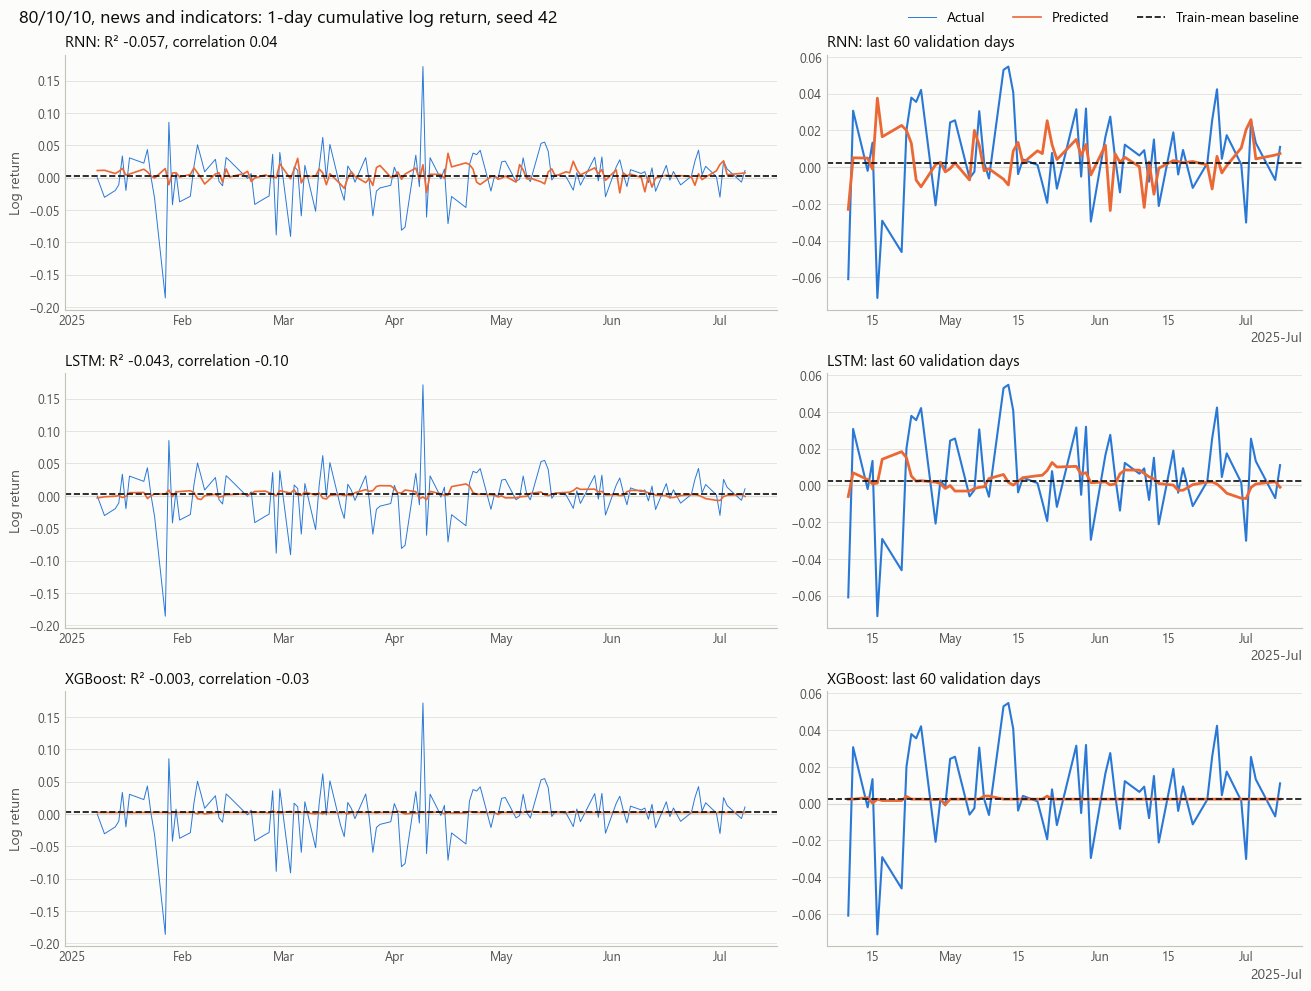

In [17]:
plot_validation_fit(
    split_predictions[split_predictions["track"] == NEWS_WITH_FEATURES_AND_TECH],
    title="80/10/10, news and indicators",
);

## Direct comparisons

The same model on two input sets, day by day. Positive differences favor the first one named. An interval that includes 0 means they can't be told apart.

**News vs no news, no features is the main test of news**, since news is the only difference between them. There are 12 comparisons per evaluation, so one interval excluding 0 isn't conclusive by itself.

### Direct comparisons: walk-forward table

MSE values are shown multiplied by 10,000.

In [18]:
walk_forward_comparisons = compare_tracks(walk_forward)
walk_forward_comparisons.to_csv(RESULTS_DIR / "unified_walk_forward_comparisons.csv", index=False)
scale_mse(walk_forward_comparisons, ["mse_first", "mse_second", "mse_improvement", "mse_improvement_lower", "mse_improvement_upper"]).drop(columns=["first_track", "second_track", "horizon"])

,comparison,model,days,mse_first,mse_second,mse_improvement,mse_improvement_lower,mse_improvement_upper,accuracy_first,accuracy_second,direction_gain,direction_gain_lower,direction_gain_upper
0,"News vs no news, no features",RNN,781,12.3274,12.1328,-0.1946,-0.3980,0.0110,0.5111,0.5173,-0.6146,-3.1248,1.8182
1,"News vs no news, no features",LSTM,781,11.8562,11.7814,-0.0748,-0.3115,0.1517,0.5150,0.5027,1.2292,-0.8451,3.4065
2,"News vs no news, no features",XGBoost,781,11.7920,11.8736,0.0816,-0.0525,0.2330,0.5124,0.5206,-0.8195,-2.2023,0.5378
3,"Indicators vs no news, no features",RNN,781,12.1005,12.1328,0.0323,-0.2363,0.3133,0.5260,0.5173,0.8707,-0.6921,2.4072
4,"Indicators vs no news, no features",LSTM,781,12.0072,11.7814,-0.2258,-0.4596,-0.0208,0.4973,0.5027,-0.5378,-2.4078,1.1012
5,"Indicators vs no news, no features",XGBoost,781,11.8933,11.8736,-0.0198,-0.1774,0.1335,0.5229,0.5206,0.2305,-1.7414,2.1261
6,News + indicators vs indicators,RNN,781,12.4166,12.1005,-0.3161,-0.5877,-0.0512,0.5132,0.5260,-1.2804,-3.3560,0.6914
7,News + indicators vs indicators,LSTM,781,11.8571,12.0072,0.1502,-0.1319,0.4698,0.5088,0.4973,1.1524,-0.6152,2.8169
8,News + indicators vs indicators,XGBoost,781,11.7495,11.8933,0.1439,-0.0140,0.3114,0.5262,0.5229,0.3329,-1.4853,1.8700
9,News + indicators vs news,RNN,781,12.4166,12.3274,-0.0892,-0.4233,0.2309,0.5132,0.5111,0.2049,-1.5877,2.0237


### Direct comparisons: walk-forward chart

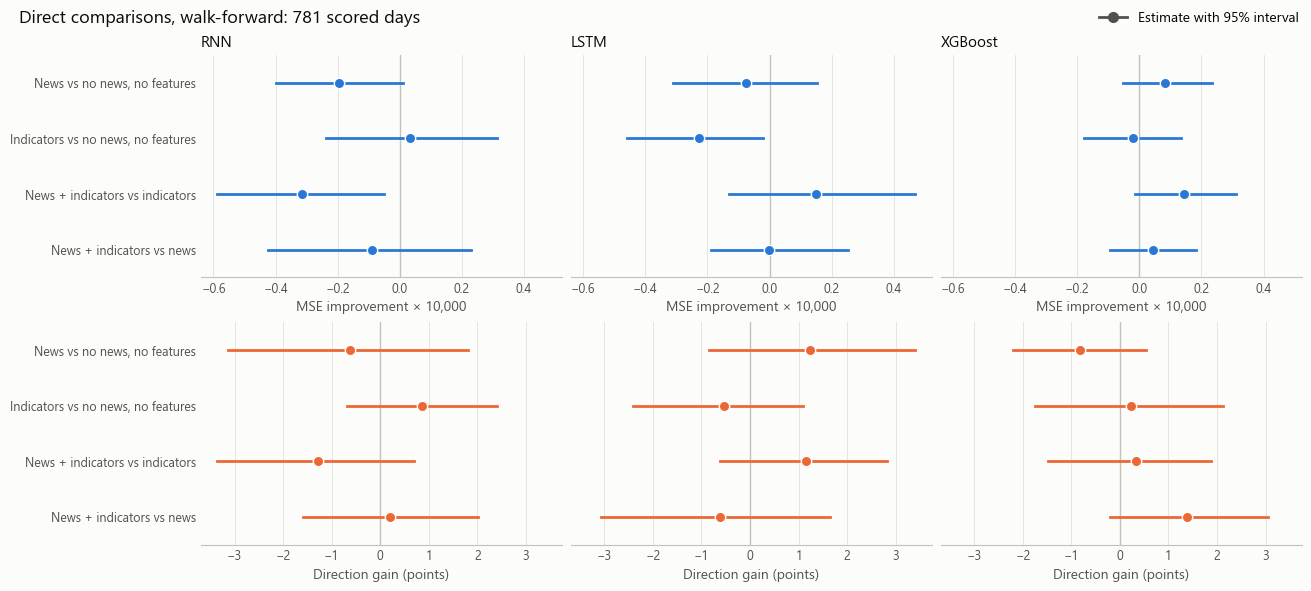

In [19]:
plot_track_comparisons(walk_forward_comparisons, title="Direct comparisons, walk-forward: 781 scored days")

### Direct comparisons: 80/10/10 table

MSE values are shown multiplied by 10,000.

In [20]:
split_comparisons = compare_tracks(split_validation)
split_comparisons.to_csv(RESULTS_DIR / "unified_split_comparisons.csv", index=False)
scale_mse(split_comparisons, ["mse_first", "mse_second", "mse_improvement", "mse_improvement_lower", "mse_improvement_upper"]).drop(columns=["first_track", "second_track", "horizon"])

,comparison,model,days,mse_first,mse_second,mse_improvement,mse_improvement_lower,mse_improvement_upper,accuracy_first,accuracy_second,direction_gain,direction_gain_lower,direction_gain_upper
0,"News vs no news, no features",RNN,123,15.8029,15.2795,-0.5234,-1.2811,0.1224,0.5024,0.5691,-6.6667,-12.1951,-1.6260
1,"News vs no news, no features",LSTM,123,15.2461,14.9350,-0.3111,-0.5046,-0.1290,0.5236,0.5610,-3.7398,-6.0163,-1.1382
2,"News vs no news, no features",XGBoost,123,15.1210,15.1226,0.0017,-0.0619,0.0635,0.5480,0.5545,-0.6504,-1.4634,0.0000
3,"Indicators vs no news, no features",RNN,123,14.9214,15.2795,0.3581,-0.1154,1.0129,0.5789,0.5691,0.9756,-3.2561,6.0163
4,"Indicators vs no news, no features",LSTM,123,14.8621,14.9350,0.0729,-0.0935,0.2240,0.5626,0.5610,0.1626,-3.0894,3.0894
5,"Indicators vs no news, no features",XGBoost,123,15.1067,15.1226,0.0160,-0.0581,0.0819,0.5610,0.5545,0.6504,-0.4878,1.7886
6,News + indicators vs indicators,RNN,123,15.7810,14.9214,-0.8596,-1.5863,-0.2162,0.5463,0.5789,-3.2520,-7.8049,0.6504
7,News + indicators vs indicators,LSTM,123,15.1339,14.8621,-0.2719,-0.4729,-0.0828,0.5463,0.5626,-1.6260,-5.3659,2.9268
8,News + indicators vs indicators,XGBoost,123,15.1102,15.1067,-0.0035,-0.1049,0.1004,0.5642,0.5610,0.3252,-0.9756,1.6301
9,News + indicators vs news,RNN,123,15.7810,15.8029,0.0219,-0.5303,0.5788,0.5463,0.5024,4.3902,0.4878,8.1301


### Direct comparisons: 80/10/10 chart

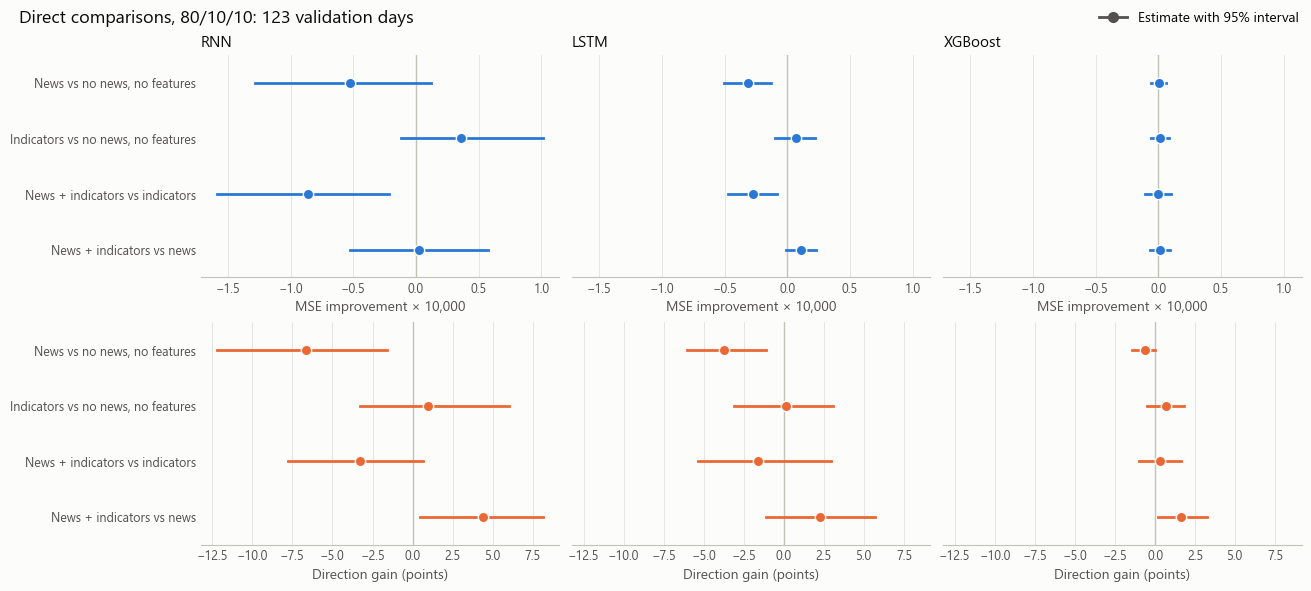

In [21]:
plot_track_comparisons(split_comparisons, title="Direct comparisons, 80/10/10: 123 validation days")

## Stopping behaviour

### Stopping: epochs and trees used

`best_step` is the epoch or tree count whose weights are used. Very low values mean a model learned almost nothing before stopping, and the stopping slice is only about 60-130 days per round.

In [22]:
FIT_KEYS = ["track", "model", "seed", "round"]
fits = walk_forward.drop_duplicates(FIT_KEYS)
(
    fits.assign(stopped_within_3=fits["best_step"] <= 3)
    .groupby(["track", "model"], sort=False)
    .agg(
        best_step_mean=("best_step", "mean"),
        best_step_min=("best_step", "min"),
        best_step_max=("best_step", "max"),
        steps_run_mean=("steps_run", "mean"),
        share_best_within_3=("stopped_within_3", "mean"),
    )
)

best_step_mean  best_step_min  best_step_max  steps_run_mean  share_best_within_3
track                                  model                                                                                     
no_news_no_feature_engineering         RNN              7.3500              1             22         17.3500               0.4000
                                       LSTM             8.5750              1             60         18.5750               0.6250
                                       XGBoost         34.1750              1            166         64.1750               0.3000
no_news_with_feature_engineering       RNN              6.9000              1             22         16.9000               0.5000
                                       LSTM             7.4500              1             27         17.4500               0.5750
                                       XGBoost         40.1000              1            289         70.1000               0.2500
news_with_feature_engineering          RNN              5.4750              1             15         15.4750               0.4250
                                       LSTM             3.8750              1             22         13.8750               0.7500
                                       XGBoost         24.7750              1            187         54.7750               0.3750
news_with_feature_engineering_and_tech RNN              4.9750              1             13         14.9750               0.4250
                                       LSTM             3.0750              1             12         13.0750               0.7500
                                       XGBoost         20.3500              1            103         50.3500               0.2500

### Stopping: are predictions flat?

`spread_ratio` is prediction spread divided by actual spread, so values near 0 mean a nearly flat line. Better MSE from flatter predictions isn't real skill.

In [23]:
summary = score_walk_forward(walk_forward).groupby(["track", "model"], sort=False)[["spread_ratio", "correlation"]].mean()
summary["share_predicted_up"] = (
    walk_forward.assign(up=walk_forward["predicted"] > 0).groupby(["track", "model"], sort=False)["up"].mean()
)
summary

spread_ratio  correlation  share_predicted_up
track                                  model                                                 
no_news_no_feature_engineering         RNN            0.2584       0.0258              0.6351
                                       LSTM           0.1514      -0.0052              0.7278
                                       XGBoost        0.1330      -0.0537              0.8038
no_news_with_feature_engineering       RNN            0.2871       0.0581              0.5734
                                       LSTM           0.2037      -0.0014              0.6981
                                       XGBoost        0.1453      -0.0423              0.7944
news_with_feature_engineering          RNN            0.2830       0.0171              0.5823
                                       LSTM           0.1560      -0.0173              0.6602
                                       XGBoost        0.1213      -0.0385              0.8138
news_with_feature_engineering_and_tech RNN            0.3149       0.0366              0.5634
                                       LSTM           0.1524      -0.0173              0.6650
                                       XGBoost        0.1113      -0.0361              0.8108

## Before and after

### Before and after: walk-forward

`before` is the earlier walk-forward run of the Phase 2 setup, which had no early stopping for RNN and LSTM. On the news track, its XGBoost was v2, with last-day news. The new input set has no earlier run.

In [24]:
before = pd.read_csv(RESULTS_DIR / "walk_forward_phase2_intervals.csv").replace({"model": {"XGBoost (v2)": "XGBoost"}})
COLUMNS = ["oos_r2", "directional_accuracy"]
intervals.merge(before, on=["track", "model"], how="left", suffixes=("_after", "_before"))[
    ["track", "model", "oos_r2_before", "oos_r2_after", "directional_accuracy_before", "directional_accuracy_after"]
]

,track,model,oos_r2_before,oos_r2_after,directional_accuracy_before,directional_accuracy_after
0,no_news_no_feature_engineering,RNN,-0.0796,-0.0532,0.5316,0.5173
1,no_news_no_feature_engineering,LSTM,-0.0439,-0.0227,0.5060,0.5027
2,no_news_no_feature_engineering,XGBoost,-0.0873,-0.0307,0.5132,0.5206
3,no_news_with_feature_engineering,RNN,-0.1136,-0.0504,0.5181,0.5260
4,no_news_with_feature_engineering,LSTM,-0.2599,-0.0423,0.5104,0.4973
5,no_news_with_feature_engineering,XGBoost,-0.0905,-0.0324,0.5227,0.5229
6,news_with_feature_engineering,RNN,-0.1289,-0.0701,0.4976,0.5111
7,news_with_feature_engineering,LSTM,-0.1971,-0.0292,0.5088,0.5150
8,news_with_feature_engineering,XGBoost,-0.0274,-0.0236,0.5193,0.5124
9,news_with_feature_engineering_and_tech,RNN,NaN,-0.0778,NaN,0.5132
